# Milestone 3 - Task 8: Final Model Comparison and Selection

## Objective

Summarize every model evaluated in Milestone 3 across every metric, select the final model, and justify the choice.

**This notebook consolidates results from Tasks 2-5 and the feature-selection experiments. It does not train or refit any models.** All numbers are held-out test results from the same 80/20 stratified split (`random_state=42`, 30,803 training / 7,701 test campaigns).

## Feature decision and how results are organized

The team decided to include the `updates` feature (the number of campaign updates), based on Challenge Advisor guidance and the feature-selection experiments. It is the single most informative feature: it adds about 11 accuracy points to every model.

The Task 6 comparison placed Logistic Regression (trained **with** `updates`) next to Random Forest, KNN and XGBoost (trained **without** it), so the roughly 10-point gap came from the feature, not the algorithm. To compare fairly, every model is reported on the same feature set, in two tables:

- **Table 1 - primary results (with `updates`):** goal, duration, levels, updates, category, subcategory, state.
- **Table 2 - robustness check (without `updates`):** the same features minus `updates`. This shows how much performance depends on `updates`, because the historical data may include updates posted *after* launch.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)

## 1. Recorded results

Each row is the tuned (or final) version of that model, evaluated once on the test set. Confusion-matrix counts are stored as TN, FP, FN, TP (class order: Failed, Successful).

Sources: Task 2 (Logistic Regression) and the feature-selection experiments notebook; Task 3 (Random Forest); Task 4 (KNN, K=41); Task 5 (XGBoost 3.4.1 and LightGBM 4.7.0), plus the `_with_updates` reruns of Tasks 3, 4 and 5.

In [2]:
cols = ["Model", "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "TN", "FP", "FN", "TP"]

# Table A: pre-launch features (no "updates")
table_a = pd.DataFrame([
    ["Logistic Regression", 0.6860, 0.6910, 0.7713, 0.7289, 0.7463, 2032, 1454,  964, 3251],
    ["Random Forest",       0.7028, 0.7024, 0.7929, 0.7449, 0.7606, 2070, 1416,  873, 3342],
    ["KNN (K=41)",          0.6520, 0.6567, 0.7630, 0.7059, 0.7049, 1805, 1681,  999, 3216],
    ["XGBoost",             0.7033, 0.7024, 0.7945, 0.7456, 0.7670, 2067, 1419,  866, 3349],
    ["LightGBM",            0.7016, 0.7015, 0.7917, 0.7440, 0.7650, 2066, 1420,  878, 3337],
], columns=cols)

# Table B: with the "updates" feature
table_b = pd.DataFrame([
    ["Logistic Regression", 0.8025, 0.8203, 0.8185, 0.8194, 0.8804, 2730,  756,  765, 3450],
    ["Random Forest",       0.8148, 0.8182, 0.8508, 0.8341, 0.8920, 2689,  797,  629, 3586],
    ["KNN (K=41)",          0.7651, 0.7755, 0.8033, 0.7892, 0.8407, 2506,  980,  829, 3386],
    ["XGBoost",             0.8139, 0.8226, 0.8415, 0.8319, 0.8981, 2721,  765,  668, 3547],
    ["LightGBM",            0.8163, 0.8227, 0.8467, 0.8346, 0.8976, 2717,  769,  646, 3569],
], columns=cols)

for t in (table_a, table_b):
    # Share of failed campaigns correctly identified (specificity)
    t["Failed Detected"] = t["TN"] / (t["TN"] + t["FP"])

metric_cols = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "Failed Detected"]

### Table 1 - primary results (with `updates`)

In [3]:
table_b.set_index("Model")[metric_cols].round(3)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Failed Detected
Model,,,,,,
Logistic Regression,0.802,0.820,0.818,0.819,0.880,0.783
Random Forest,0.815,0.818,0.851,0.834,0.892,0.771
KNN (K=41),0.765,0.776,0.803,0.789,0.841,0.719
XGBoost,0.814,0.823,0.842,0.832,0.898,0.781
LightGBM,0.816,0.823,0.847,0.835,0.898,0.779


### Table 2 - robustness check (without `updates`)

In [4]:
table_a.set_index("Model")[metric_cols].round(3)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Failed Detected
Model,,,,,,
Logistic Regression,0.686,0.691,0.771,0.729,0.746,0.583
Random Forest,0.703,0.702,0.793,0.745,0.761,0.594
KNN (K=41),0.652,0.657,0.763,0.706,0.705,0.518
XGBoost,0.703,0.702,0.794,0.746,0.767,0.593
LightGBM,0.702,0.702,0.792,0.744,0.765,0.593


## 2. Visual comparison

Each chart shows the five standard metrics for every model. ROC-AUC is the most useful single number here because it does not depend on the 0.5 decision threshold.

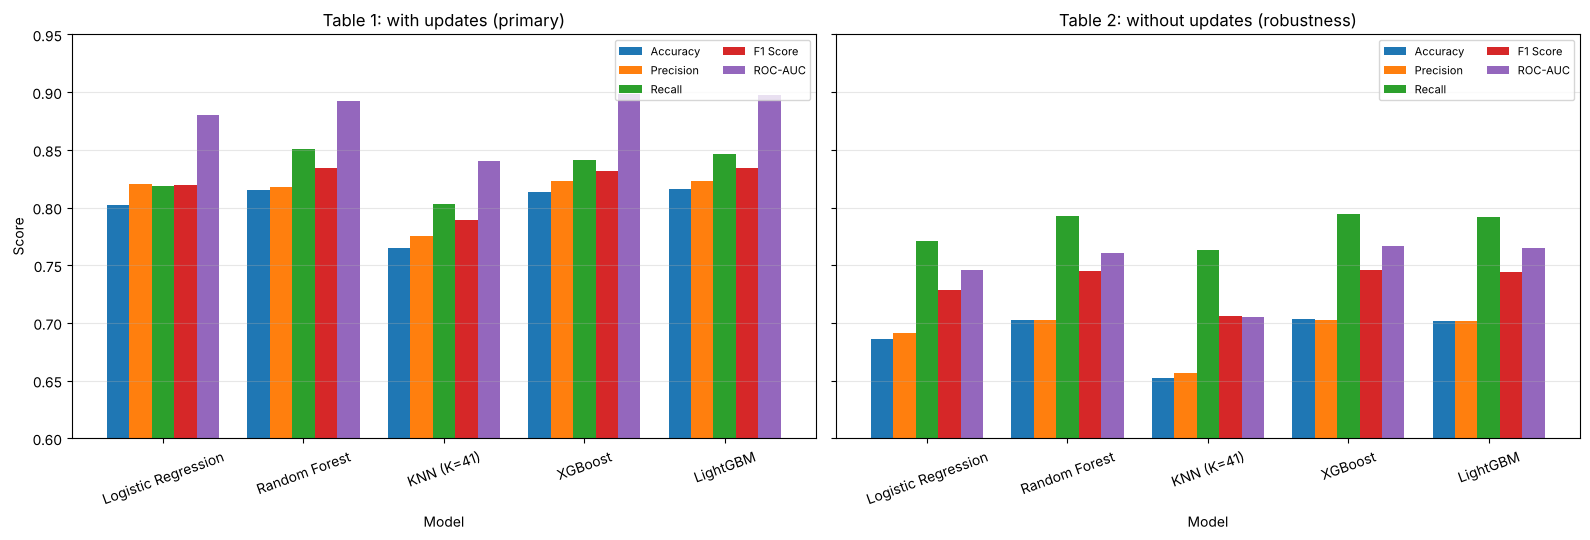

In [5]:
plot_metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
for ax, (title, tbl) in zip(axes, [("Table 1: with updates (primary)", table_b),
                                    ("Table 2: without updates (robustness)", table_a)]):
    tbl.set_index("Model")[plot_metrics].plot(kind="bar", ax=ax, rot=20, width=0.8)
    ax.set_title(title)
    ax.set_ylabel("Score")
    ax.set_ylim(0.6, 0.95)
    ax.legend(loc="upper right", fontsize=8, ncol=2)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

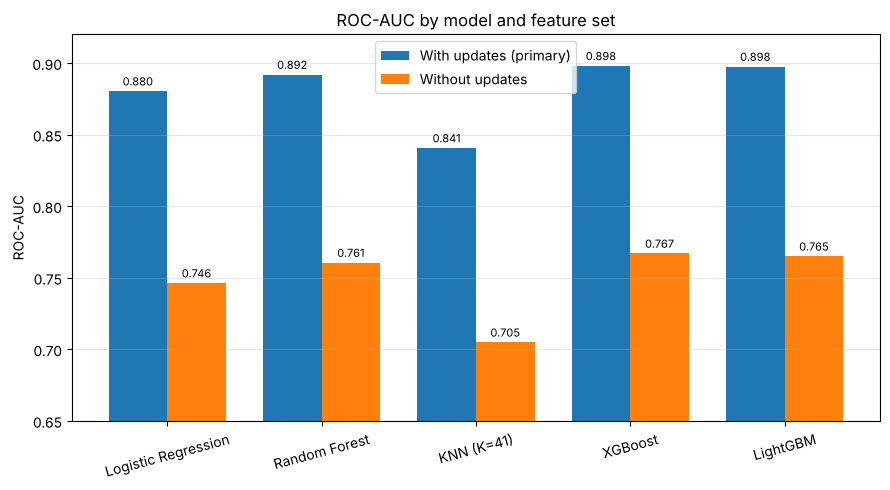

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(table_a))
w = 0.38
ax.bar(x - w/2, table_b["ROC-AUC"], w, label="With updates (primary)")
ax.bar(x + w/2, table_a["ROC-AUC"], w, label="Without updates")
ax.set_xticks(x)
ax.set_xticklabels(table_a["Model"], rotation=15)
ax.set_ylim(0.65, 0.92)
ax.set_ylabel("ROC-AUC")
ax.set_title("ROC-AUC by model and feature set")
for i, (b, a) in enumerate(zip(table_b["ROC-AUC"], table_a["ROC-AUC"])):
    ax.text(i - w/2, b + 0.004, f"{b:.3f}", ha="center", fontsize=8)
    ax.text(i + w/2, a + 0.004, f"{a:.3f}", ha="center", fontsize=8)
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 3. What the comparison shows

1. **The `updates` feature matters more than the algorithm.** Adding it lifts every model by about 11-12 accuracy points and 0.13-0.14 ROC-AUC. Differences between algorithms are small by comparison.
2. **On equal features the ranking is stable.** XGBoost, LightGBM and Random Forest form the top group (with updates ROC-AUC 0.892-0.898; without updates 0.761-0.767), Logistic Regression is next, and KNN is last in both tables.
3. **The top group is effectively tied.** Gaps of 0.001-0.006 ROC-AUC and 0.001-0.003 accuracy are within the noise expected from a single test split, so these models cannot be separated on metrics alone.
4. **Logistic Regression only looked best in Task 6 because of the feature mismatch.** On equal features it trails the tree-based models in both tables.
5. **Tuning gave small gains.** Tuning XGBoost improved ROC-AUC by about 0.005 over its default, and a second, wider search added nothing. Performance is limited by the available features, not by hyperparameters.
6. **Failed campaigns are the weak spot.** Without `updates`, every model identifies only 52-60% of failed campaigns (they lean toward predicting success). With `updates`, this rises to roughly 77-78% for the leading models.

## 4. Final model selection

**Selected model: XGBoost (tuned)** - `learning_rate=0.1`, `max_depth=3`, `n_estimators=400` (XGBoost 3.4.1).

**Why XGBoost**

- **Highest ROC-AUC in both tables** (0.898 with updates, 0.767 without), tied with LightGBM within noise.
- **Chosen with cross-validation, not the test set.** Hyperparameters were selected by 5-fold CV ROC-AUC on the training data only, and the test set was used once. CV ROC-AUC was 0.762 without updates, close to the 0.767 test result, so there is no sign of overfitting.
- **Robust to the feature decision.** It is the strongest or tied-strongest model whether or not `updates` is used, so the choice does not hinge on that decision.
- **Strong, balanced precision and recall.** With updates its F1 (0.832) is within 0.003 of the best (LightGBM, 0.835). Without updates it has the highest F1 of any model (0.746; recall 0.795, precision 0.702).
- **Well supported.** It handles the mixed numeric and one-hot features in the shared pipeline without extra work, and it comes with a tuning record (two search rounds) showing the result is stable.

**Why not the others**

- **LightGBM** is statistically tied with XGBoost (ROC-AUC 0.898 vs 0.898 with updates; 0.765 vs 0.767 without). It would be an equally defensible choice; XGBoost was selected because it was marginally ahead on the without-updates ROC-AUC and its tuning was documented more thoroughly.
- **Random Forest** is close on accuracy but about 0.006 lower in ROC-AUC with updates and 0.006 lower without updates.
- **Logistic Regression** is the most interpretable baseline (and is what the SHAP analysis explains), but trails on every metric once features are equal.
- **KNN** is weakest in both tables and is also the slowest to score new campaigns.

## 5. Limitations and next steps

- **`updates` and timing.** The dataset may count updates posted after launch, so a creator using the tool before launching would not yet have this number. The team decided to use `updates`; Table 2 shows the cost of leaving it out (about 70% accuracy, ROC-AUC 0.767) and should be cited alongside the main result. Updates may also partly be a *result* of a campaign doing well, so they are best read as an association, not as a lever a creator can pull.
- **Accuracy target.** The with-updates model reaches 0.814 accuracy, meeting the roughly 80% target in the challenge brief. Without `updates`, accuracy is capped near 70%, because other post-launch columns (backers, pledged amount, comments) were deliberately excluded to avoid leakage.
- **Failed-campaign detection.** Even with `updates`, the best models identify only about 78% of failed campaigns (about 59% without). For Milestone 4, class weighting or a tuned decision threshold may help catch more failures at the cost of more false alarms.
- **Single test split.** Differences smaller than roughly 0.01 ROC-AUC should not be over-interpreted; repeated cross-validation would give tighter estimates if a finer ranking is needed.
- **Interpretability.** The SHAP analysis explains the Logistic Regression model. If XGBoost is carried forward, a SHAP analysis with `TreeExplainer` on the XGBoost model would explain the model actually selected.

## 6. Summary

| | With `updates` (primary) | Without `updates` |
|---|---|---|
| Final model | XGBoost (tuned) | XGBoost (tuned) |
| Accuracy | 0.814 | 0.703 |
| ROC-AUC | 0.898 | 0.767 |
| Recall | 0.842 | 0.795 |
| F1 | 0.832 | 0.746 |

XGBoost is selected as the final model. LightGBM and Random Forest perform within noise of it, and the biggest lever for performance is the `updates` feature, not the choice of algorithm.